# Фінальний проєкт. Завдання №4 — Візуалізація проходження воронки

**Автор:** Мойсеєнко Світлана · **Дисципліна:** Продуктова аналітика та прикладна статистика (GoIT Neoversity)

**Контекст.** Компанія тестує новий підхід до розміщення онлайн-реклами. Контрольна група (`Control Campaign`) працює як раніше, тестова (`Test Campaign`) — за новим підходом. Для кожної групи є поденні дані за 30 днів серпня 2019 р.: витрати, покази, охоплення та проходження воронки продажів (кліки → пошук → перегляд контенту → кошик → покупка).

**Мета ноутбука:** візуалізувати воронку для тестової та контрольної груп, порівняти конверсії між кроками та зробити висновки.

Дані завантажуються з локальної папки `data/` (копії файлів з умови), а за її відсутності — безпосередньо з Google Drive за посиланнями з завдання.

In [1]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

warnings.filterwarnings("ignore")
pd.set_option("display.precision", 4)

C_TEST, C_CONTROL = "#2a78d6", "#eb6834"
C_INK, C_MUTED, C_GRID = "#0b0b0b", "#898781", "#e1e0d9"
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#c3c2b7", "axes.labelcolor": C_INK, "xtick.color": C_MUTED, "ytick.color": C_MUTED,
    "axes.grid": True, "grid.color": C_GRID, "grid.linewidth": 0.8, "axes.axisbelow": True, "font.size": 10,
})

URLS = {
    "Control": "https://drive.google.com/uc?export=download&id=1OlboUFclx-9QAakDNUAMzQquH8tNzo07",
    "Test": "https://drive.google.com/uc?export=download&id=1fFIA1tJj5YQs2G7tv244tgzLhpJ5axoG",
}
FILES = {"Control": "data/control_group.csv", "Test": "data/test_group.csv"}
RENAME = {"Campaign Name": "campaign", "Date": "date", "Spend [USD]": "spend", "# of Impressions": "impressions",
          "Reach": "reach", "# of Website Clicks": "clicks", "# of Searches": "searches",
          "# of View Content": "view_content", "# of Add to Cart": "add_to_cart", "# of Purchase": "purchase"}
STEPS = ["impressions", "reach", "clicks", "searches", "view_content", "add_to_cart", "purchase"]
STEP_UA = {"impressions": "Покази", "reach": "Охоплення", "clicks": "Кліки на сайт", "searches": "Пошук на сайті",
           "view_content": "Перегляд контенту", "add_to_cart": "Додавання в кошик", "purchase": "Покупка"}

def load_group(group):
    local = Path(FILES[group])
    d = pd.read_csv(local if local.exists() else URLS[group], sep=";").rename(columns=RENAME)
    d["date"] = pd.to_datetime(d["date"], format="%d.%m.%Y")
    d["group"] = group
    return d

df = pd.concat([load_group("Control"), load_group("Test")], ignore_index=True)
row_ok = df[STEPS].notna().all(axis=1)
# день використовуємо лише тоді, коли повні дані є в ОБОХ групах — щоб порівнювати однакові періоди
df["complete"] = row_ok.groupby(df["date"]).transform("all")
print(f"Рядків: {len(df)}; рядків з пропусками: {(~row_ok).sum()}; "
      f"днів, виключених з аналізу для обох груп: {df.loc[~df.complete, 'date'].nunique()}")
df[~row_ok]

Рядків: 60; рядків з пропусками: 1; днів, виключених з аналізу для обох груп: 1


,campaign,date,spend,impressions,reach,clicks,searches,view_content,add_to_cart,purchase,group,complete
4,Control Campaign,2019-08-05,1835,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Control,False


У контрольній групі за **5 серпня** є лише витрати, а показники воронки відсутні. Щоб порівнювати групи за **однаковий період**, цей день виключаємо з аналізу для обох груп — залишається по 29 днів у кожній. Інакше суми за 30 днів тестової групи порівнювалися б із сумами за 29 днів контрольної, що зміщувало б результат на користь тестової групи.

In [2]:
d = df[df.complete].copy()
tot = d.groupby("group")[["spend"] + STEPS].sum().T[["Control", "Test"]]
tot.index = ["Витрати, $"] + [STEP_UA[s] for s in STEPS]
tot.astype(int)

group,Control,Test
"Витрати, $",66818,74595
Покази,3177233,2123249
Охоплення,2576503,1509609
Кліки на сайт,154303,175107
Пошук на сайті,64418,70463
Перегляд контенту,56370,54882
Додавання в кошик,37700,25490
Покупка,15161,14869


## 1. Воронка: абсолютні значення

Класична воронка «ширина = кількість користувачів на кроці». Покази та охоплення — показники реклами, тому воронку сайту починаємо з кліків: саме з цього моменту користувач потрапляє на сайт.

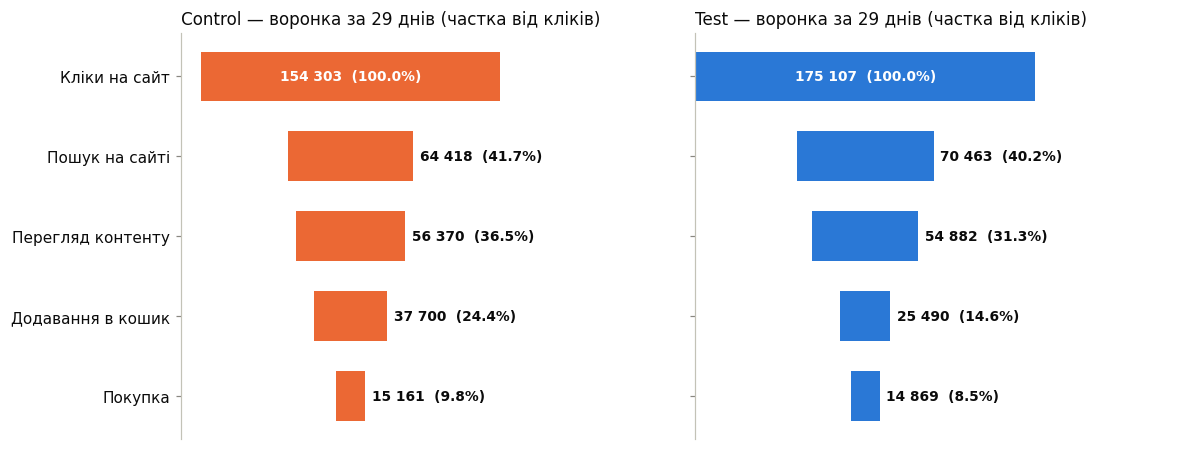

In [3]:
funnel_steps = ["clicks", "searches", "view_content", "add_to_cart", "purchase"]
F = d.groupby("group")[funnel_steps].sum().T[["Control", "Test"]]

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), sharey=True)
for ax, (grp, color) in zip(axes, [("Control", C_CONTROL), ("Test", C_TEST)]):
    vals = F[grp].to_numpy()
    top = F.max().max()
    y = np.arange(len(funnel_steps))[::-1]
    ax.barh(y, vals, left=(top - vals) / 2, height=0.62, color=color)
    for yi, v, s in zip(y, vals, funnel_steps):
        share = v / vals[0]
        label = f"{int(v):,}".replace(",", " ") + f"  ({share:.1%})"
        if v > top * 0.6:   # широкий сегмент — підпис усередині
            ax.text(top / 2, yi, label, ha="center", va="center", color="white", fontsize=9, fontweight="bold")
        else:               # вузький сегмент — підпис праворуч від нього
            ax.text((top + v) / 2 + top * 0.02, yi, label, ha="left", va="center", color=C_INK, fontsize=9, fontweight="bold")
    ax.set_xlim(0, top * 1.45)
    ax.set_yticks(y); ax.set_yticklabels([STEP_UA[s] for s in funnel_steps], color=C_INK)
    ax.set_xticks([]); ax.grid(False); ax.spines["bottom"].set_visible(False)
    ax.set_title(f"{grp} — воронка за 29 днів (частка від кліків)", loc="left", color=C_INK, fontsize=11)
plt.tight_layout(); plt.show()

## 2. Конверсії між кроками (step-to-step) та від кліку до кожного кроку

In [4]:
def conv_table(F):
    rows = []
    for i in range(1, len(funnel_steps)):
        prev, cur = funnel_steps[i - 1], funnel_steps[i]
        rows.append({"Крок": f"{STEP_UA[prev]} → {STEP_UA[cur]}",
                     "Control": F.loc[cur, "Control"] / F.loc[prev, "Control"],
                     "Test": F.loc[cur, "Test"] / F.loc[prev, "Test"]})
    rows.append({"Крок": "Клік → Покупка (наскрізна)", "Control": F.loc["purchase", "Control"] / F.loc["clicks", "Control"],
                 "Test": F.loc["purchase", "Test"] / F.loc["clicks", "Test"]})
    out = pd.DataFrame(rows).set_index("Крок")
    out["Різниця, п.п."] = (out["Test"] - out["Control"]) * 100
    return out

conv = conv_table(F)
conv.style.format({"Control": "{:.1%}", "Test": "{:.1%}", "Різниця, п.п.": "{:+.1f}"})

,Control,Test,"Різниця, п.п."
Крок,,,
Кліки на сайт → Пошук на сайті,41.7%,40.2%,-1.5
Пошук на сайті → Перегляд контенту,87.5%,77.9%,-9.6
Перегляд контенту → Додавання в кошик,66.9%,46.4%,-20.4
Додавання в кошик → Покупка,40.2%,58.3%,+18.1
Клік → Покупка (наскрізна),9.8%,8.5%,-1.3


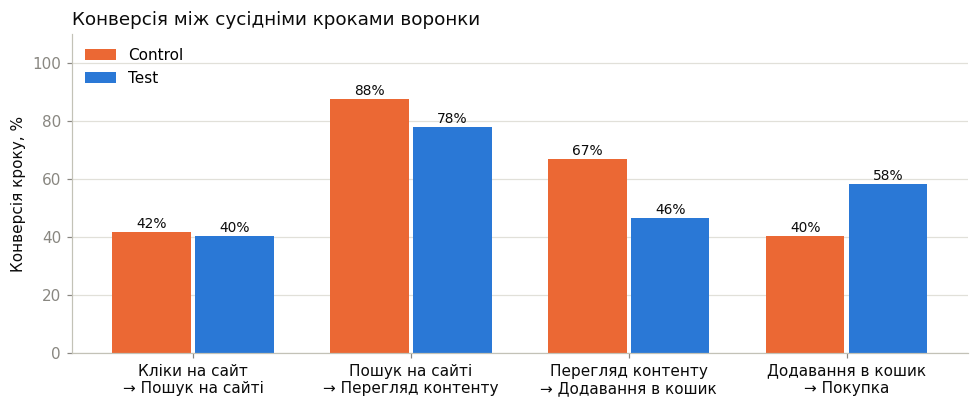

In [5]:
fig, ax = plt.subplots(figsize=(9, 3.8))
labels = conv.index[:-1]
x = np.arange(len(labels)); w = 0.36
for i, (grp, color) in enumerate([("Control", C_CONTROL), ("Test", C_TEST)]):
    bars = ax.bar(x + (i - 0.5) * (w + 0.02), conv[grp].iloc[:-1] * 100, width=w, color=color, label=grp)
    for b in bars:
        ax.text(b.get_x() + b.get_width() / 2, b.get_height() + 1.5, f"{b.get_height():.0f}%", ha="center",
                fontsize=9, color=C_INK)
ax.set_xticks(x); ax.set_xticklabels([l.replace(" → ", "\n→ ") for l in labels], color=C_INK)
ax.set_ylabel("Конверсія кроку, %"); ax.set_ylim(0, 110); ax.grid(axis="x", visible=False)
ax.set_title("Конверсія між сусідніми кроками воронки", loc="left", color=C_INK)
ax.legend(frameon=False, loc="upper left"); plt.tight_layout(); plt.show()

## 3. Верхня частина воронки: реклама → сайт

Воронка сайту не показує, звідки беруться кліки. Додамо рекламні показники: покази, охоплення, CTR і вартість кліку.

In [6]:
ad = pd.DataFrame({
    "Control": [tot.loc["Витрати, $", "Control"], tot.loc["Покази", "Control"], tot.loc["Охоплення", "Control"], tot.loc["Кліки на сайт", "Control"]],
    "Test": [tot.loc["Витрати, $", "Test"], tot.loc["Покази", "Test"], tot.loc["Охоплення", "Test"], tot.loc["Кліки на сайт", "Test"]],
}, index=["Витрати, $", "Покази", "Охоплення", "Кліки"])
ad.loc["CTR (кліки / покази)"] = ad.loc["Кліки"] / ad.loc["Покази"]
ad.loc["Частота (покази / охоплення)"] = ad.loc["Покази"] / ad.loc["Охоплення"]
ad.loc["CPC, $"] = ad.loc["Витрати, $"] / ad.loc["Кліки"]
ad.loc["CPA, $ за покупку"] = ad.loc["Витрати, $"] / tot.loc["Покупка"]
ad["Test / Control"] = ad["Test"] / ad["Control"]
ad.round(3)

,Control,Test,Test / Control
"Витрати, $",6.6818e+04,7.4595e+04,1.116
Покази,3.1772e+06,2.1232e+06,0.668
Охоплення,2.5765e+06,1.5096e+06,0.586
Кліки,1.5430e+05,1.7511e+05,1.135
CTR (кліки / покази),4.9000e-02,8.2000e-02,1.698
Частота (покази / охоплення),1.2330e+00,1.4060e+00,1.141
"CPC, $",4.3300e-01,4.2600e-01,0.984
"CPA, $ за покупку",4.4070e+00,5.0170e+00,1.138


## 4. Динаміка воронки по днях

Сумарні цифри можуть приховувати нестабільність. Подивимось на щоденні покупки та ключові конверсії.

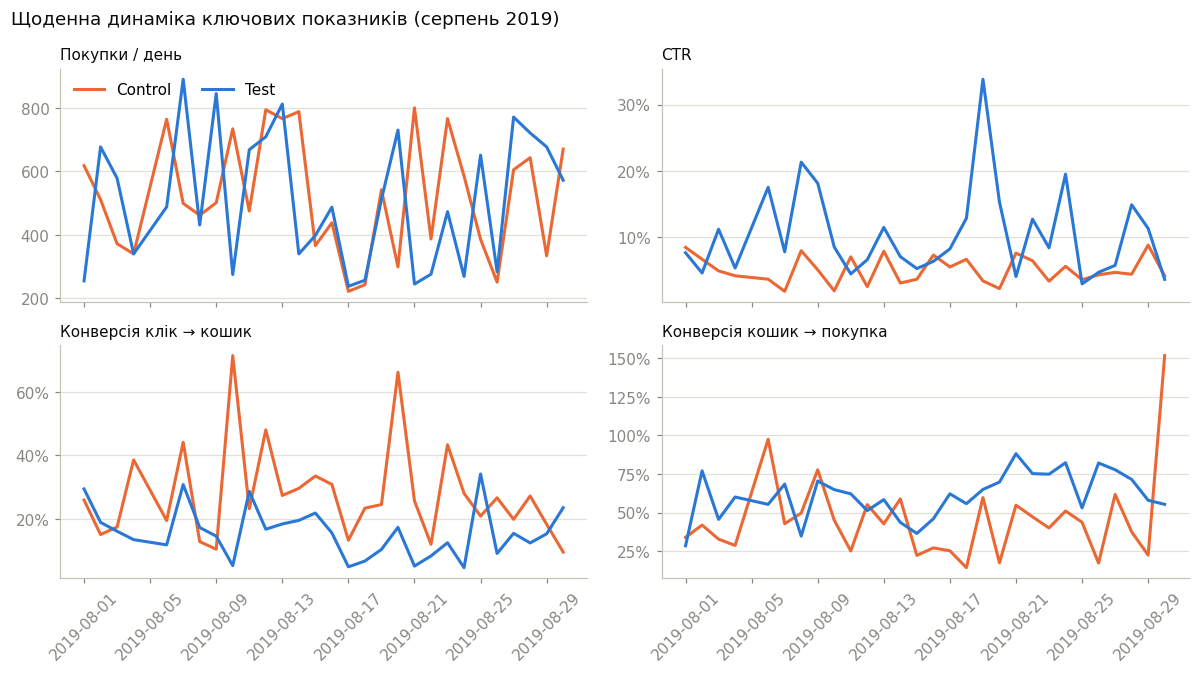

Дні, коли покупок більше, ніж додавань у кошик:


,group,date,add_to_cart,purchase
29,Control,2019-08-30,442.0,670.0


In [7]:
d["ctr"] = d.clicks / d.impressions
d["cart_rate"] = d.add_to_cart / d.clicks
d["cr_cart"] = d.purchase / d.add_to_cart
d["cr_click"] = d.purchase / d.clicks

fig, axes = plt.subplots(2, 2, figsize=(11, 6.2), sharex=True)
panels = [("purchase", "Покупки / день", "{:.0f}"), ("ctr", "CTR", "{:.0%}"),
          ("cart_rate", "Конверсія клік → кошик", "{:.0%}"), ("cr_cart", "Конверсія кошик → покупка", "{:.0%}")]
for ax, (m, title, fmt) in zip(axes.ravel(), panels):
    for grp, color in [("Control", C_CONTROL), ("Test", C_TEST)]:
        s = d[d.group == grp].set_index("date")[m]
        ax.plot(s.index, s.values, color=color, lw=2, label=grp)
    ax.set_title(title, loc="left", color=C_INK, fontsize=10)
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _, f=fmt: f.format(v)))
    ax.grid(axis="x", visible=False)
axes[0, 0].legend(frameon=False, loc="upper left", ncol=2)
for ax in axes[1]:
    ax.tick_params(axis="x", rotation=45)
fig.suptitle("Щоденна динаміка ключових показників (серпень 2019)", x=0.01, ha="left", color=C_INK)
plt.tight_layout(); plt.show()

anom = d[d.purchase > d.add_to_cart][["group", "date", "add_to_cart", "purchase"]]
print("Дні, коли покупок більше, ніж додавань у кошик:"); anom

## Висновки

1. **Новий підхід змінив форму воронки, а не її результат.** За 29 порівнюваних днів тестова група отримала **≈ 14.9 тис. покупок проти ≈ 15.2 тис. у контрольній** (−1.9 %, у середньому ≈ 513 проти ≈ 523 покупок на день — різниця в межах випадкових коливань), хоча витрати тестової групи були на **≈ 12 % вищими** за той самий період.
2. **Верх воронки працює ефективніше.** Тестова кампанія показувалася значно рідше (≈ 2.1 млн показів проти ≈ 3.2 млн) і охоплювала на ≈ 41 % менше людей, але її **CTR удвічі вищий (≈ 8.3 % проти ≈ 4.9 %)**, тож кліків на сайт стало більше (≈ 175 тис. проти ≈ 154 тис., +13 %) за майже однакової вартості кліку (≈ $0.43). Нове розміщення приводить більш «клікабельну» аудиторію.
3. **Середина воронки просідає.** Частка кліків, що доходять до кошика, у тестовій групі **≈ 14.6 % проти ≈ 24.4 %** — найбільша втрата нового підходу. Найсильніше падає крок перегляд контенту → кошик (≈ 46 % проти ≈ 67 %): нова аудиторія частіше клікає й переглядає товари, але рідше знаходить те, що хоче купити.
4. **Низ воронки, навпаки, сильніший.** Ті, хто таки додав товар у кошик, у тестовій групі купують значно частіше: **≈ 58 % проти ≈ 40 %**. Разом ці два ефекти майже компенсують одне одного, і наскрізна конверсія клік → покупка у тестовій групі трохи нижча (≈ 8.5 % проти ≈ 9.8 %).
5. **Вартість покупки (CPA) у тестовій групі вища** (≈ $5.0 проти ≈ $4.4, +14 %) через більші витрати при тій самій кількості покупок. Отже, з погляду ефективності витрат новий підхід **не кращий за поточний**.
6. **Якість даних.** В одному дні контрольної групи (30.08) покупок більше, ніж додавань у кошик, ще в одному (06.08) вони майже рівні — імовірно, похибка трекінгу або покупки без кроку «кошик» (швидка покупка). Також 05.08 у контролі відсутні дані воронки. Такі аномалії треба перевіряти з командою трекінгу до прийняття рішень (див. трекінг-план у Завданні №2).

**Продуктовий висновок:** новий підхід варто не впроваджувати «як є», а доопрацювати середину воронки для нової аудиторії (релевантність посадкової сторінки/каталогу під очікування від реклами). Якщо вдасться підняти конверсію клік → кошик хоча б до рівня контролю, поєднання вищого CTR і вищої конверсії кошик → покупка дасть істотний приріст покупок за ті самі витрати. Статистична перевірка відмінностей — у Завданнях №3 та №5.